# Parent Paper 1: Implementation and Steam Check

**Parent paper:** D. Gray, A. Shalan, and C. Kadlec, "Sales Predictions for Video Games Using Predictive Analytics of Market Data," *IEEE CICN 2024*, pp. 1510–1516. [IEEE Xplore](https://ieeexplore.ieee.org/document/10847429)

The paper built its models in Orange Data Mining 3.36.2, a visual tool, so it has no code to download. This notebook implements its method in Python with scikit-learn.

The notebook has two parts:

1. **Part 1** runs the method on the paper's own dataset, the Kaggle *Video Game Sales and Ratings* data. It reproduces each numerical table in the paper's Sections III and IV:
   - Table I: feature statistics
   - Table II: Test and Score results
   - Table III: Linear Regression coefficients
   - Table IV: predicted against original sales
2. **Part 2** runs the same models on the Steam Games Dataset, using the Steam variables closest to the paper's inputs, to check whether the result carries over.

In [1]:
import json
import os
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 5078
pd.set_option("display.float_format", "{:.4f}".format)

PAPER_CSV = os.path.join("..", "old_analysis", "paper_replication", "video_game_sales_and_ratings.csv")
STEAM_GAMES = "steam_appids.csv.gz"  # app IDs of the 76,727 games kept by new_analysis/notebooks/01

### Helper functions

These helpers run the simple version of the method: an 80/20 split with the same two models and metrics. Part 2 (Steam) uses them, and so does the hold-out check at the end of Part 1. MAPE skips games whose true value is zero, to avoid dividing by zero.

In [2]:
def metrics(y_true, y_pred):
    nonzero = y_true != 0
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])) * 100,
        "R2": r2_score(y_true, y_pred),
    }


def run_paper_method(X, y):
    """80/20 split, Linear Regression and Decision Tree, the paper's metrics."""
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    models = {"Linear Regression": LinearRegression(),
              "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE)}
    table, predictions = {}, {}
    for name, model in models.items():
        model.fit(X_train, y_train)
        predictions[name] = model.predict(X_test)
        table[name] = metrics(y_test, predictions[name])
    return pd.DataFrame(table).T, models, y_test, predictions


def coefficient_table(model, features):
    return pd.DataFrame({"Coefficient": [model.intercept_, *model.coef_]}, index=["(Intercept)", *features])


def plot_predictions(y_test, predictions, title, unit):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, (name, pred) in zip(axes, predictions.items()):
        ax.scatter(y_test, pred, s=6, alpha=0.4)
        lim = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
        ax.plot(lim, lim, color="black", linewidth=1)
        ax.set_title(f"{name} (R² = {r2_score(y_test, pred):.3f})")
        ax.set_xlabel(f"Actual {unit}")
        ax.set_ylabel(f"Predicted {unit}")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

---
## Part 1: Implementation on the paper's dataset

**Data.** Kaggle *Video Game Sales and Ratings* ([link](https://www.kaggle.com/datasets/thedevastator/video-game-sales-and-rating)). This mirror has 16,719 rows; the paper reports 16,928, because reposts of this dataset differ slightly.

**Inputs (the paper's Table III):**

- `index` (the row number)
- `Year_of_Release`
- Regional sales: `NA_Sales`, `EU_Sales`, `JP_Sales` and `Other_Sales`
- Critic and user data: `Critic_Score`, `Critic_Count` and `User_Count`

**Target:** `Global_Sales`, in millions of units.

**How Orange's defaults are matched.** The paper used Orange's *Test and Score* widget with default settings and does not mention dropping rows, so this implementation keeps all rows and copies Orange's behavior:

| Orange (paper) | This notebook |
|---|---|
| Test and Score: 10-fold cross-validation | `KFold(n_splits=10, shuffle=True)` |
| Linear Regression fills missing values with the column mean | `SimpleImputer(strategy="mean")` before `LinearRegression()` |
| Tree defaults: at least 2 games per leaf, no split below 5 games, depth limit 100 | `DecisionTreeRegressor(min_samples_leaf=2, min_samples_split=5, max_depth=100)` |
| Platform and Genre turned into text, so not used | Not used |
| MAPE reported as a fraction (0.032) | MAPE as a fraction |
| Final model trained on all rows for Tables III and IV | `LinearRegression` refit on all rows |

In [3]:
paper_df = pd.read_csv(PAPER_CSV).reset_index()  # the paper uses the row index as an input
PAPER_FEATURES = ["index", "Year_of_Release", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales",
                  "Critic_Score", "Critic_Count", "User_Count"]
PAPER_TARGET = "Global_Sales"
print(f"Rows: {len(paper_df):,}   Columns: {paper_df.shape[1] - 1}")
paper_df.head()

Rows: 16,719   Columns: 16


,index,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,0,Wii Sports,Wii,2006.0000,Sports,Nintendo,41.3600,28.9600,3.7700,8.4500,82.5300,76.0000,51.0000,8,322.0000,Nintendo,E
1,1,Super Mario Bros.,NES,1985.0000,Platform,Nintendo,29.0800,3.5800,6.8100,0.7700,40.2400,NaN,NaN,NaN,NaN,NaN,NaN
2,2,Mario Kart Wii,Wii,2008.0000,Racing,Nintendo,15.6800,12.7600,3.7900,3.2900,35.5200,82.0000,73.0000,8.3,709.0000,Nintendo,E
3,3,Wii Sports Resort,Wii,2009.0000,Sports,Nintendo,15.6100,10.9300,3.2800,2.9500,32.7700,80.0000,73.0000,8,192.0000,Nintendo,E
4,4,Pokemon Red/Pokemon Blue,GB,1996.0000,Role-Playing,Nintendo,11.2700,8.8900,10.2200,1.0000,31.3700,NaN,NaN,NaN,NaN,NaN,NaN


### Table I: feature statistics

These are the same statistics as the paper's Table I, computed on all rows. The paper's own values are shown alongside for comparison.

In [4]:
stats_cols = PAPER_FEATURES + [PAPER_TARGET]
table1 = pd.DataFrame({
    "Mean": paper_df[stats_cols].mean(),
    "Mode": paper_df[stats_cols].mode().iloc[0],
    "Median": paper_df[stats_cols].median(),
    "Min": paper_df[stats_cols].min(),
    "Max": paper_df[stats_cols].max(),
    "Missing": paper_df[stats_cols].isna().sum(),
})
table1["Missing (%)"] = (table1["Missing"] / len(paper_df) * 100).round(0)

paper_table1 = pd.DataFrame({  # values printed in the paper's Table I
    "Paper mean":    [8463.50, 2006.485, 0.2664, 0.1469, 0.0782, 0.0479, 69.038, 26.429, 163.270, 0.5395],
    "Paper median":  [8463.50, 2007.0, 0.08, 0.02, 0.00, 0.01, 71.0, 22.0, 25.0, 0.17],
    "Paper max":     [16927, 2020, 41.36, 28.96, 10.22, 10.57, 98.0, 113.0, 10665, 82.53],
    "Paper missing": [0, 273, 0, 0, 0, 0, 8668, 8668, 9210, 0],
}, index=stats_cols)
pd.set_option("display.float_format", "{:.4f}".format)
table1.join(paper_table1)

,Mean,Mode,Median,Min,Max,Missing,Missing (%),Paper mean,Paper median,Paper max,Paper missing
index,8359.0000,0.0000,8359.0000,0.0000,16718.0000,0,0.0000,8463.5000,8463.5000,16927.0000,0
Year_of_Release,2006.4874,2008.0000,2007.0000,1980.0000,2020.0000,269,2.0000,2006.4850,2007.0000,2020.0000,273
NA_Sales,0.2633,0.0000,0.0800,0.0000,41.3600,0,0.0000,0.2664,0.0800,41.3600,0
EU_Sales,0.1450,0.0000,0.0200,0.0000,28.9600,0,0.0000,0.1469,0.0200,28.9600,0
JP_Sales,0.0776,0.0000,0.0000,0.0000,10.2200,0,0.0000,0.0782,0.0000,10.2200,0
Other_Sales,0.0473,0.0000,0.0100,0.0000,10.5700,0,0.0000,0.0479,0.0100,10.5700,0
Critic_Score,68.9677,70.0000,71.0000,13.0000,98.0000,8582,51.0000,69.0380,71.0000,98.0000,8668
Critic_Count,26.3608,4.0000,21.0000,3.0000,113.0000,8582,51.0000,26.4290,22.0000,113.0000,8668
User_Count,162.2299,4.0000,24.0000,4.0000,10665.0000,9129,55.0000,163.2700,25.0000,10665.0000,9210
Global_Sales,0.5335,0.0200,0.1700,0.0100,82.5300,0,0.0000,0.5395,0.1700,82.5300,0


The statistics match the paper closely. The small gaps come from this copy having 16,719 rows against the paper's 16,928, for example 269 against 273 missing release years.

### Table II: Test and Score results (10-fold cross-validation)

In [5]:
def paper_metrics(y_true, y_pred):
    nonzero = y_true != 0
    return {"MSE": mean_squared_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE": np.mean(np.abs((y_true[nonzero] - y_pred[nonzero]) / y_true[nonzero])),
            "R2": r2_score(y_true, y_pred)}


X_paper, y_paper = paper_df[PAPER_FEATURES], paper_df[PAPER_TARGET]
orange_models = {
    "Decision Tree": make_pipeline(SimpleImputer(strategy="mean"),
                                   DecisionTreeRegressor(min_samples_leaf=2, min_samples_split=5, max_depth=100,
                                                         random_state=RANDOM_STATE)),
    "Linear Regression": make_pipeline(SimpleImputer(strategy="mean"), LinearRegression()),
}
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_pred = {name: cross_val_predict(model, X_paper, y_paper, cv=cv) for name, model in orange_models.items()}
table2 = pd.DataFrame({name: paper_metrics(y_paper, pred) for name, pred in cv_pred.items()}).T

paper_table2 = pd.DataFrame({"MSE": [0.147, 0.000], "RMSE": [0.383, 0.005], "MAE": [0.008, 0.003],
                             "MAPE": [0.010, 0.032], "R2": [0.939, 1.000]},
                            index=["Decision Tree", "Linear Regression"])
pd.set_option("display.float_format", "{:.3f}".format)
pd.concat({"This notebook": table2, "Paper (Table II)": paper_table2}, axis=1)

This notebook                         Paper (Table II)  \
                            MSE  RMSE   MAE  MAPE    R2              MSE   
Decision Tree             0.210 0.459 0.009 0.001 0.912            0.147   
Linear Regression         0.000 0.005 0.003 0.033 1.000            0.000   

                                           
                   RMSE   MAE  MAPE    R2  
Decision Tree     0.383 0.008 0.010 0.939  
Linear Regression 0.005 0.003 0.032 1.000

Linear Regression matches the paper on every metric and comes out best, with R² = 1.000.

The Decision Tree is close but less stable. Its score depends on which fold the few best-selling games land in and on how ties between splits are broken. The paper does not report its random seed, so the next cell repeats the tree's cross-validation with 20 different seeds.

In [6]:
seed_r2 = []
for seed in range(20):
    tree = make_pipeline(SimpleImputer(strategy="mean"),
                         DecisionTreeRegressor(min_samples_leaf=2, min_samples_split=5, max_depth=100, random_state=seed))
    pred = cross_val_predict(tree, X_paper, y_paper, cv=KFold(n_splits=10, shuffle=True, random_state=seed))
    seed_r2.append(r2_score(y_paper, pred))
seed_r2 = np.array(seed_r2)
print("Decision Tree R² over 20 seeds:", np.round(seed_r2, 3))
print(f"Mean {seed_r2.mean():.3f}, range {seed_r2.min():.3f} to {seed_r2.max():.3f}  (paper: 0.939)")

Decision Tree R² over 20 seeds: [0.946 0.921 0.942 0.917 0.901 0.933 0.917 0.92  0.923 0.912 0.939 0.928
 0.888 0.945 0.931 0.911 0.917 0.935 0.935 0.937]
Mean 0.925, range 0.888 to 0.946  (paper: 0.939)


The paper's Decision Tree score of 0.939 falls within the range of these 20 runs. The remaining differences are small. The Decision Tree's MAPE (0.001 here against 0.010 in the paper) is the largest; the likely reason is that Orange uses its own tree implementation, which differs in detail from scikit-learn's.

### Table III: Linear Regression coefficients

As in the paper, the final Linear Regression is trained on all rows.

In [7]:
final_lr = make_pipeline(SimpleImputer(strategy="mean"), LinearRegression()).fit(X_paper, y_paper)
lr = final_lr[-1]
table3 = pd.DataFrame({
    "This notebook": [lr.intercept_, *lr.coef_],
    "Paper (Table III)": [0.0291607, 7.3995e-08, -1.47341e-05, 0.999977, 1.00006, 1.00001, 0.999779,
                          1.68683e-06, -2.7194e-06, -6.76926e-08],
}, index=["intercept", *PAPER_FEATURES])
pd.set_option("display.float_format", "{:.6g}".format)
table3

,This notebook,Paper (Table III)
intercept,0.0321669,0.0291607
index,8.17378e-08,7.3995e-08
Year_of_Release,-1.63019e-05,-1.47341e-05
NA_Sales,0.999974,0.999977
EU_Sales,1.0001,1.00006
JP_Sales,1.00002,1.00001
Other_Sales,0.999819,0.999779
Critic_Score,2.81937e-06,1.68683e-06
Critic_Count,-2.86862e-06,-2.7194e-06
User_Count,-3.59246e-08,-6.76926e-08


The coefficients match the paper's in size and sign:

- Each regional sales column has a weight of about 1.
- Year of release has a small negative weight.
- `index`, critic score, critic count and user count have weights close to zero.

### Table IV: predicted against original sales

These are the final model's predictions for the first ten games in the dataset.

In [8]:
paper_df["LR_Prediction"] = final_lr.predict(X_paper)
table4 = paper_df[["Name", "Platform", "Year_of_Release", PAPER_TARGET, "LR_Prediction"]].head(10).copy()
table4["Error"] = table4["LR_Prediction"] - table4[PAPER_TARGET]
pd.set_option("display.float_format", "{:.4f}".format)
table4

,Name,Platform,Year_of_Release,Global_Sales,LR_Prediction,Error
0,Wii Sports,Wii,2006.0000,82.5300,82.5398,0.0098
1,Super Mario Bros.,NES,1985.0000,40.2400,40.2395,-0.0005
2,Mario Kart Wii,Wii,2008.0000,35.5200,35.5197,-0.0003
3,Wii Sports Resort,Wii,2009.0000,32.7700,32.7696,-0.0004
4,Pokemon Red/Pokemon Blue,GB,1996.0000,31.3700,31.3803,0.0103
5,Tetris,GB,1989.0000,30.2600,30.2594,-0.0006
6,New Super Mario Bros.,DS,2006.0000,29.8000,29.7997,-0.0003
7,Wii Play,Wii,2006.0000,28.9200,28.9096,-0.0104
8,New Super Mario Bros. Wii,Wii,2009.0000,28.3200,28.3194,-0.0006
9,Duck Hunt,NES,1984.0000,28.3100,28.3092,-0.0008


### Why the score is near 1

In [9]:
regional_sum = paper_df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum(axis=1)
gap = (paper_df[PAPER_TARGET] - regional_sum).abs()
print(f"Largest gap between Global_Sales and the sum of the four regions: {gap.max():.3f} M units")
print(f"Correlation between Global_Sales and the regional sum:           {np.corrcoef(regional_sum, paper_df[PAPER_TARGET])[0, 1]:.6f}")

Largest gap between Global_Sales and the sum of the four regions: 0.020 M units
Correlation between Global_Sales and the regional sum:           0.999994


`Global_Sales` is the sum of the four regional columns, up to rounding. That is why each regional column gets a weight of 1 and Linear Regression reaches R² = 1.000: the model is adding up columns, not learning what drives sales. Regional sales, critic counts and user counts also exist only after a game has been on sale, so this model cannot forecast a new release.

### Check: 80/20 hold-out on complete rows

As a robustness check, the same two models are run in the simpler way used for Steam in Part 2: drop rows with missing values (6,894 remain), train on 80% and test on 20%, with default tree settings.

In [10]:
paper_model_df = paper_df[PAPER_FEATURES + [PAPER_TARGET]].dropna().reset_index(drop=True)
paper_results, paper_models, paper_y_test, paper_pred = run_paper_method(
    paper_model_df[PAPER_FEATURES], paper_model_df[PAPER_TARGET])
paper_results

,MSE,RMSE,MAE,MAPE (%),R2
Linear Regression,0.0000,0.0059,0.0038,3.0219,1.0000
Decision Tree,0.0022,0.0466,0.0049,0.1013,0.9988


The result does not depend on the evaluation setup: Linear Regression stays at R² = 1.000 on complete rows with a hold-out test set.

---
## Part 2: The same method on the Steam dataset

**Data.** Steam Games Dataset ([link](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)), Kaggle, version 49. It combines Steam store pages with SteamSpy ownership estimates. Part 2 uses the 76,727 games that remain after the cleaning in my main analysis ([`new_analysis/notebooks/01`](../new_analysis/notebooks/01_preprocessing_and_transformation.ipynb)). Their Steam app IDs are saved in [`steam_appids.csv.gz`](steam_appids.csv.gz) in this folder.

**Target.** Steam publishes no sales figures. SteamSpy reports owners as ranges, such as 20,000–50,000, so each game is given the midpoint of its range. This target is the Steam stand-in for `Global_Sales`.

**Inputs.** Steam has no regional sales, so the closest after-release variables stand in for the paper's inputs:

| Paper input | Steam stand-in |
|---|---|
| `index` | row number |
| `Year_of_Release` | release year |
| `NA/EU/JP/Other_Sales` | positive reviews, negative reviews, recommendations, peak concurrent players |
| `Critic_Score` | Metacritic score (0 = no score) |
| `Critic_Count`, `User_Count` | average playtime, user score |

Like the paper's inputs, these are all measured after release. Unlike regional sales, none of them adds up to the target.

In [11]:
path = kagglehub.dataset_download("fronkongames/steam-games-dataset/versions/49")
with open(os.path.join(path, "games.json"), encoding="utf8") as f:
    raw = json.load(f)

keep = set(pd.read_csv(STEAM_GAMES, usecols=["appid"])["appid"])
rows = []
for appid, g in raw.items():
    if int(appid) not in keep:
        continue
    low, high = (int(x) for x in g["estimated_owners"].split(" - "))
    rows.append({
        "appid": int(appid),
        "release_year": pd.to_datetime(g["release_date"], errors="coerce").year,
        "positive_reviews": g["positive"],
        "negative_reviews": g["negative"],
        "recommendations": g["recommendations"],
        "peak_ccu": g["peak_ccu"],
        "metacritic_score": g["metacritic_score"],
        "avg_playtime": g["average_playtime_forever"],
        "user_score": g["user_score"],
        "owners": (low + high) / 2,
    })
del raw

steam_df = pd.DataFrame(rows).dropna().reset_index(drop=True).reset_index()  # "index" = row number, as in the paper
STEAM_FEATURES = ["index", "release_year", "positive_reviews", "negative_reviews", "recommendations",
                  "peak_ccu", "metacritic_score", "avg_playtime", "user_score"]
STEAM_TARGET = "owners"
print(f"Steam games used: {len(steam_df):,}")
steam_df[STEAM_FEATURES + [STEAM_TARGET]].describe().T

Steam games used: 76,727


,count,mean,std,min,25%,50%,75%,max
index,76727.0000,38363.0000,22149.3214,0.0000,19181.5000,38363.0000,57544.5000,76726.0000
release_year,76727.0000,2019.9702,3.0611,1997.0000,2018.0000,2020.0000,2022.0000,2024.0000
positive_reviews,76727.0000,1569.3337,35184.2597,0.0000,3.0000,15.0000,84.0000,7642084.0000
negative_reviews,76727.0000,254.7964,6769.4430,0.0000,1.0000,4.0000,24.0000,1173003.0000
recommendations,76727.0000,1383.3341,27262.3526,0.0000,0.0000,0.0000,0.0000,4830455.0000
peak_ccu,76727.0000,70.2442,4598.4135,0.0000,0.0000,0.0000,0.0000,1013936.0000
metacritic_score,76727.0000,3.8328,16.5080,0.0000,0.0000,0.0000,0.0000,97.0000
avg_playtime,76727.0000,283.7173,14124.7780,0.0000,0.0000,0.0000,40.0000,3429544.0000
user_score,76727.0000,0.0392,1.7632,0.0000,0.0000,0.0000,0.0000,100.0000
owners,76727.0000,125614.9074,1584161.7392,10000.0000,10000.0000,10000.0000,35000.0000,150000000.0000


### Table II on Steam: model performance (target = estimated owners)

In [12]:
steam_results, steam_models, steam_y_test, steam_pred = run_paper_method(
    steam_df[STEAM_FEATURES], steam_df[STEAM_TARGET])
steam_results

,MSE,RMSE,MAE,MAPE (%),R2
Linear Regression,686276431397.5631,828418.0294,95605.4103,274.7782,0.5693
Decision Tree,879135528802.2937,937622.2741,78685.3252,93.8945,0.4483


### Table III on Steam: Linear Regression coefficients

In [13]:
coefficient_table(steam_models["Linear Regression"], STEAM_FEATURES)

,Coefficient
(Intercept),20460120.9505
index,-0.1096
release_year,-10107.1197
positive_reviews,41.8151
negative_reviews,187.4242
recommendations,-29.9658
peak_ccu,-165.7996
metacritic_score,6669.0786
avg_playtime,2.6029
user_score,-521.5386


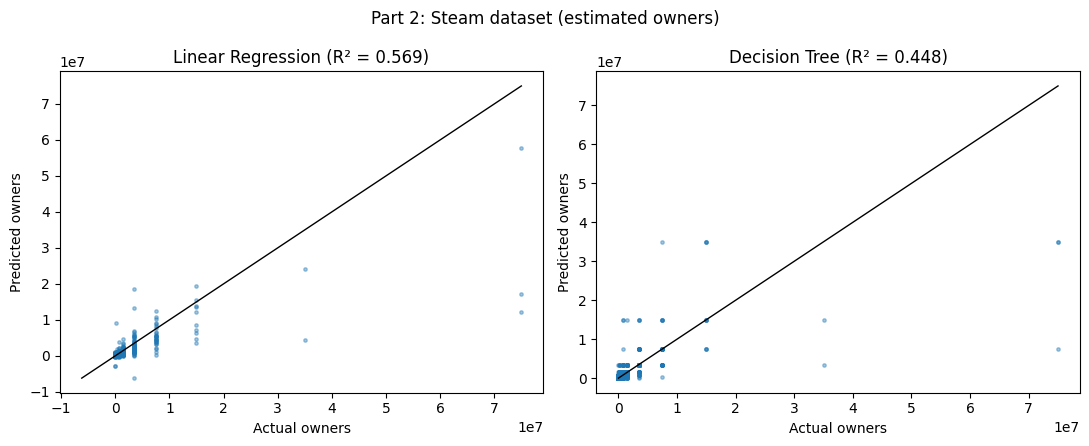

In [14]:
plot_predictions(steam_y_test, steam_pred, "Part 2: Steam dataset (estimated owners)", "owners")

### An extra check: log scale

Owner counts are very skewed. Most games have under 20,000 owners, while a few have tens of millions, so a handful of huge games dominate the raw-scale errors. Here the same method is run again with the target and the count inputs on a log scale.

In [15]:
log_cols = ["positive_reviews", "negative_reviews", "recommendations", "peak_ccu", "avg_playtime"]
X_log = steam_df[STEAM_FEATURES].copy()
X_log[log_cols] = np.log1p(X_log[log_cols])
steam_log_results, _, _, _ = run_paper_method(X_log, np.log1p(steam_df[STEAM_TARGET]))
steam_log_results

,MSE,RMSE,MAE,MAPE (%),R2
Linear Regression,0.5377,0.7333,0.5165,5.0423,0.6585
Decision Tree,0.7951,0.8917,0.4770,4.6011,0.4951


---
## Comparison

In [16]:
comparison = pd.DataFrame({
    "Paper (reported)": {"Linear Regression": 1.000, "Decision Tree": 0.939},
    "Part 1: 10-fold CV (Orange setup)": table2["R2"],
    "Part 1: 80/20 hold-out": paper_results["R2"],
    "Part 2: Steam, owners (80/20)": steam_results["R2"],
    "Part 2: Steam, log owners (80/20)": steam_log_results["R2"],
})
comparison.index.name = "R²"
pd.set_option("display.float_format", "{:.3f}".format)
comparison

,Paper (reported),Part 1: 10-fold CV (Orange setup),Part 1: 80/20 hold-out,"Part 2: Steam, owners (80/20)","Part 2: Steam, log owners (80/20)"
R²,,,,,
Decision Tree,0.939,0.912,0.999,0.448,0.495
Linear Regression,1.000,1.000,1.000,0.569,0.659


## Summary

**Part 1 reproduces the paper.** With Orange's default setup (10-fold cross-validation, mean-filled missing values, Orange's tree settings), the results match the paper's Table II closely:

| Model | Paper's R² | My R² |
|---|---|---|
| Linear Regression | 1.000 | 1.000 (RMSE 0.005, same as the paper) |
| Decision Tree | 0.939 | 0.912 in the main run; 0.89 to 0.95 over 20 seeds, average 0.92 |

The feature statistics (Table I) and the coefficients (Table III) also match. Each regional sales column gets a weight of about 1, which shows the score comes from `Global_Sales` being the sum of its four regions.

**Part 2 does not carry over to Steam.** The same method with the closest after-release Steam variables gives:

| Target | Linear Regression | Decision Tree |
|---|---|---|
| Estimated owners | 0.57 | 0.45 |
| Log owners | 0.66 | 0.50 |

These scores are well short of 1, for two reasons:

- No Steam input adds up to the number of owners.
- SteamSpy reports owners only as ranges, so the target itself is approximate.

On the raw owner scale, the score also moves a lot with the random split. A few games with tens of millions of owners dominate the errors; with another split I tried, Linear Regression scored below zero.

**Takeaway.** The paper's near-perfect score comes from its dataset, not from its method, and it relies on information that exists only after release. This is why the rest of my project predicts Steam owners from release-day information only.